### Задача A: прогноз на следующий день

Вариант 4, город для анализа - Якутск

In [1]:
# Импорт библиотек
import json
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from tensorflow.keras import Sequential, layers

# Фиксируем seed для воспроизводимости результатов
SEED = 42
EPOCHS = 60
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True


### 1.Загрузка данных
**Источник**: Open-Meteo Historical Weather API

**Период**: 2016-01-01 — 2025-12-31 (10 лет)

**Целевой показатель**: среднесуточная температура (temperature_2m_mean), °C

**Координаты Якутска**: 62.0355° с.ш., 129.6755° в.д.

Для того, чтобы не запрашивать API повторно, в коде кэшируем данные в CSV.

In [2]:
CITY = "Якутск"
LATITUDE = 62.0355
LONGITUDE = 129.6755

START_DATE = "2016-01-01"
END_DATE = "2025-12-31"

cache = Path( f"weather_{LATITUDE}_{LONGITUDE}_{START_DATE}_{END_DATE}.csv")

if cache.exists():
    df = pd.read_csv(cache, parse_dates=["date"])
else:
    params = {
        "latitude": LATITUDE,
        "longitude": LONGITUDE,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": "temperature_2m_mean",
        "timezone": "auto",
        "models": "era5",
    }

    url = ("https://archive-api.open-meteo.com/v1/archive?"+ urlencode(params))

    with urlopen(url, timeout=120) as response:
        data = json.load(response)

    df = pd.DataFrame({"date": pd.to_datetime(data["daily"]["time"]),
                        "temperature": data["daily"]["temperature_2m_mean"],
    })

    df.to_csv(cache, index=False)

print("Город:", CITY)
print("Количество записей:", len(df))
display(df.head())

Город: Якутск
Количество записей: 3653


,date,temperature
0,2016-01-01,-39.9
1,2016-01-02,-33.9
2,2016-01-03,-33.2
3,2016-01-04,-37.4
4,2016-01-05,-35.8


### 2.Первичный анализ данных

Проверяем:
1. уникальность дат — дубликаты недопустимы для временного ряда.
2. непрерывность ряда: пропуска между датами быть не должно.

Если есть пропуски — описываем, но НЕ интерполируем будущими значениями

Повторяющихся дат: 0
Отсутствующих дат: 0
Пропусков температуры: 0


,temperature
count,3653.000000
mean,-6.963811
std,21.666668
min,-53.600000
25%,-27.900000
50%,-2.700000
75%,12.900000
max,27.900000


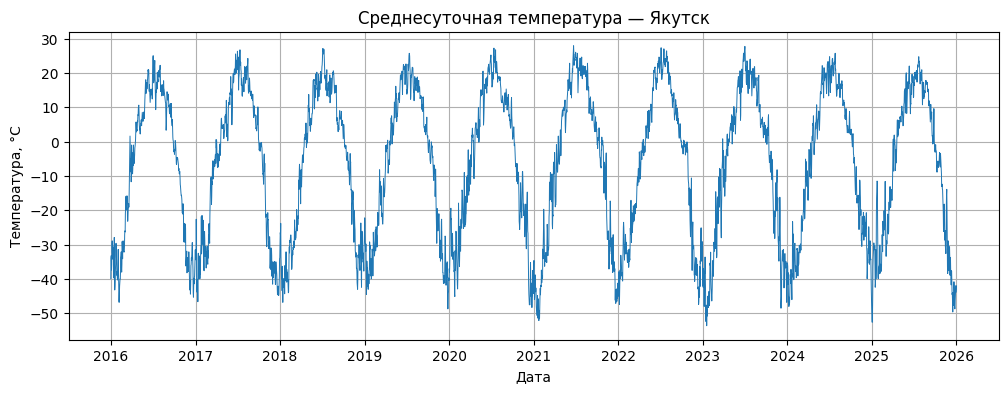

In [3]:
df = df.sort_values("date").reset_index(drop=True)

duplicates = df["date"].duplicated().sum()
print("Повторяющихся дат:", duplicates)


df = df.set_index("date")

expected_dates = pd.date_range(START_DATE, END_DATE, freq="D")
missing_dates = expected_dates.difference(df.index)

print("Отсутствующих дат:", len(missing_dates))

df = df.reindex(expected_dates)
df.index.name = "date"

print("Пропусков температуры:", df["temperature"].isna().sum())

display(df.describe())

plt.plot(df.index, df["temperature"], linewidth=0.7)
plt.title(f"Среднесуточная температура — {CITY}")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.show()

График показывает ярко выраженную сезонность:
 - зимние минимумы до -50°C, летние максимумы до +25°C
 - годовая амплитуда ~75°C (резко континентальный климат Якутска)

Это важно: модель должна улавливать сезонный паттерн.

### 3.Масштабирование и разбиение

- Хронологическое разбиение: 70% / 15% / 15%
- ВАЖНО: без перемешивания (shuffle=False), иначе будет утечка данных из будущего
- scaler обучается ТОЛЬКО на train — иначе информация из test попадёт в модель
- Для интерпретации MAE и RMSE возвращаем значения к исходной шкале °C

In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

temperature = df[["temperature"]].to_numpy(dtype=np.float32)

scaler = StandardScaler()
scaler.fit(temperature[:train_end])

scaled = scaler.transform(temperature).astype(np.float32)

splits = {
    "Train": (0, train_end),
    "Validation": (train_end, val_end),
    "Test": (val_end, n),
}

for name, (start, end) in splits.items():
    print(
        f"{name}: {df.index[start].date()} — "
        f"{df.index[end - 1].date()}, дней: {end - start}"
    )

Train: 2016-01-01 — 2022-12-31, дней: 2557
Validation: 2023-01-01 — 2024-07-01, дней: 548
Test: 2024-07-02 — 2025-12-31, дней: 548


### 4.Формирование окон

Функция ``make_windows()`` формирует обучающие примеры методом скользящего окна (sliding window).

**Логика формирования:**
- **Вход X:** последовательность `[T(t-L), ..., T(t-1)]` — значения температуры за L предыдущих дней (без дня t)
- **Целевое значение y:** T(t) — температура следующего дня

Границы train/val/test задаются хронологически без сдвига, так как горизонт прогноза равен 1 дню и целевое значение не выходит за пределы своего интервала разбиения.

In [6]:
MAX_WINDOW = 30 # максимальная длина входного окна из исследуемых

def make_windows(window):
    """
    Формирует скользящие окна для задачи A (прогноз на следующий день).
    
    Для каждого момента t формируем:
      - вход X: scaled[t-window : t]   (последние window дней)
      - выход y: scaled[t]             (температура следующего дня T(t))
    """
    # Позиции t, для которых хватает и входного окна, и целевого значения.
    target_positions = np.arange(MAX_WINDOW, len(scaled))

    # Входные окна: для каждой позиции t берём window предыдущих значений. Срез не включает i, то есть день t не попадает во вход.
    # Это предотвращает утечку: модель не «видит» то, что должна предсказать.
    X = np.array([scaled[i - window:i]
        for i in target_positions
            ], dtype=np.float32)
    
    # Целевое значение — температура в день t (следующий день относительно окна).
    # Значения в масштабированной шкале (StandardScaler, обученный на train).
    y = scaled[target_positions]

    # Хронологическое разделение:     
    # target_positions — это индексы ЦЕЛЕВЫХ значений y(t).
    # Если t < train_end, то y(t) попадает в train,
    # а все входные значения [t-window, t) гарантированно тоже в train (они ещё раньше).
    train_mask = target_positions < train_end
    val_mask = ( (target_positions >= train_end)  & (target_positions < val_end) )
    test_mask = target_positions >= val_end

    return {
        "X_train": X[train_mask],
        "y_train": y[train_mask],
        "X_val": X[val_mask],
        "y_val": y[val_mask],
        "X_test": X[test_mask],
        "y_test": y[test_mask],
        "test_dates": df.index[target_positions[test_mask]],
    }

datasets = { window: make_windows(window) 
                for window in [7, 30]}

for window, dataset in datasets.items():
    print(
        f"Окно {window}: "
        f"train {dataset['X_train'].shape}, "
        f"validation {dataset['X_val'].shape}, "
        f"test {dataset['X_test'].shape}"
    )

Окно 7: train (2527, 7, 1), validation (548, 7, 1), test (548, 7, 1)
Окно 30: train (2527, 30, 1), validation (548, 30, 1), test (548, 30, 1)


### 5.Построение моделей

**Архитектуры:**
1. MLP — базовая полносвязная сеть, вход Flatten(L, 1) → Dense → Dense(1)
2. SimpleRNN — один рекуррентный слой
3. LSTM — ячейки с механизмом забывания/сохранения
4. StackedLSTM — два LSTM-слоя, первый с return_sequences=True

**Выходная активация:** linear (регрессия непрерывной температуры).

**Функция потерь:** MSE

In [7]:
def build_model(kind, window, units, dropout, optimizer_name):
    model = Sequential([ layers.Input(shape=(window, 1)) ])

    if kind == "MLP":
        model.add(layers.Flatten())
        model.add(layers.Dense(units, activation="relu"))

    elif kind == "SimpleRNN":
        model.add(layers.SimpleRNN(units))

    elif kind == "LSTM":
        model.add(layers.LSTM(units))

    elif kind == "StackedLSTM":
        model.add(
            layers.LSTM(units, return_sequences=True)
        )
        model.add(layers.Dropout(dropout))
        model.add(layers.LSTM(units))

    else:
        raise ValueError(f"Неизвестная архитектура: {kind}")

    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))

    if optimizer_name == "Adam":
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=0.001
        )
    elif optimizer_name == "RMSprop":
        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=0.001
        )
    else:
        raise ValueError("Неизвестный оптимизатор")

    model.compile(optimizer=optimizer, loss="mse")
    return model

### 6.Эксперименты

План экспериментов:
 - Длина окна L: 7 и 30 дней (сравнение короткого и длинного контекста)
 - Число нейронов: 32 и 64
 - Dropout: 0.0 и 0.2 (проверка регуляризации)
 - Оптимизатор: Adam и RMSprop

``EarlyStopping`` с ``patience=8`` — останавливаем обучение, если validation loss не улучшается 8 эпох подряд

``restore_best_weights=True`` — возвращаем веса лучшей эпохи

``shuffle=False`` — сохраняем хронологический порядок внутри batch

In [8]:
configs = [
    (7, 32, 0.0, "Adam"),
    (30, 32, 0.0, "Adam"),
    (7, 64, 0.0, "Adam"),
    (7, 32, 0.2, "Adam"),
    (7, 32, 0.0, "RMSprop"),
]

kinds = ["MLP", "SimpleRNN", "LSTM", "StackedLSTM"]

experiments = []
best_models = {}

for kind in kinds:
    best_mae = np.inf

    for window, units, dropout, optimizer in configs:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        dataset = datasets[window]

        model = build_model( kind, window, units, dropout, optimizer )

        stopping = tf.keras.callbacks.EarlyStopping( monitor="val_loss",   patience=8,    restore_best_weights=True, )

        history = model.fit(
            dataset["X_train"],
            dataset["y_train"],
            validation_data=(
                dataset["X_val"],
                dataset["y_val"],
            ),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[stopping],
            shuffle=False,
            verbose=0,
        )

        val_prediction = scaler.inverse_transform( model.predict(dataset["X_val"], verbose=0) ).ravel()

        val_true = scaler.inverse_transform( dataset["y_val"]).ravel()

        val_mae = mean_absolute_error( val_true, val_prediction)

        row = {
            "Модель": kind,
            "Окно": window,
            "Нейроны": units,
            "Dropout": dropout,
            "Оптимизатор": optimizer,
            "Эпох": len(history.history["loss"]),
            "Лучшая эпоха": (
                int(np.argmin(history.history["val_loss"])) + 1
            ),
            "Validation MAE": val_mae,
        }

        experiments.append(row)

        if val_mae < best_mae:
            best_mae = val_mae
            best_models[kind] = {
                "config": row.copy(),
                "weights": model.get_weights(),
                "history": history.history,
            }

        print(
            f"{kind}, окно={window}, нейроны={units}, "
            f"dropout={dropout}, {optimizer}: "
            f"validation MAE={val_mae:.3f} °C"
        )

experiment_table = pd.DataFrame(experiments)
display(experiment_table.sort_values(["Модель", "Validation MAE"]))


MLP, окно=7, нейроны=32, dropout=0.0, Adam: validation MAE=2.600 °C
MLP, окно=30, нейроны=32, dropout=0.0, Adam: validation MAE=2.849 °C
MLP, окно=7, нейроны=64, dropout=0.0, Adam: validation MAE=2.553 °C
MLP, окно=7, нейроны=32, dropout=0.2, Adam: validation MAE=2.676 °C
MLP, окно=7, нейроны=32, dropout=0.0, RMSprop: validation MAE=2.664 °C
SimpleRNN, окно=7, нейроны=32, dropout=0.0, Adam: validation MAE=2.584 °C
SimpleRNN, окно=30, нейроны=32, dropout=0.0, Adam: validation MAE=2.542 °C
SimpleRNN, окно=7, нейроны=64, dropout=0.0, Adam: validation MAE=2.584 °C
SimpleRNN, окно=7, нейроны=32, dropout=0.2, Adam: validation MAE=2.564 °C
SimpleRNN, окно=7, нейроны=32, dropout=0.0, RMSprop: validation MAE=2.573 °C
LSTM, окно=7, нейроны=32, dropout=0.0, Adam: validation MAE=2.561 °C
LSTM, окно=30, нейроны=32, dropout=0.0, Adam: validation MAE=2.528 °C
LSTM, окно=7, нейроны=64, dropout=0.0, Adam: validation MAE=2.542 °C
LSTM, окно=7, нейроны=32, dropout=0.2, Adam: validation MAE=2.683 °C
LSTM

,Модель,Окно,Нейроны,Dropout,Оптимизатор,Эпох,Лучшая эпоха,Validation MAE
11,LSTM,30,32,0.0,Adam,55,47,2.528019
12,LSTM,7,64,0.0,Adam,47,39,2.541597
10,LSTM,7,32,0.0,Adam,60,59,2.561231
13,LSTM,7,32,0.2,Adam,60,60,2.683500
14,LSTM,7,32,0.0,RMSprop,55,47,2.805346
2,MLP,7,64,0.0,Adam,51,43,2.553159
0,MLP,7,32,0.0,Adam,60,56,2.600480
4,MLP,7,32,0.0,RMSprop,43,35,2.663566
3,MLP,7,32,0.2,Adam,60,59,2.676237
1,MLP,30,32,0.0,Adam,60,60,2.848714


### 7.Метрики и базовые прогнозы

Базовые прогнозы:
1. Naive (Persistence): T(t) = T(t-1) — прогноз = последнее известное значение
2. SeasonalNaive: T(t) = T(t-365) — значение год назад (для Якутска с его резкой сезонностью это сильный baseline)

Метрики считаем в исходной шкале °C (обратное масштабирование через ``scaler.inverse_transform``).

MAE и RMSE — в °C, MSE — в °C², R² — безразмерная (ориентир ≥ 0.80).

In [9]:
def calculate_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted),
    }

test_dates = datasets[7]["test_dates"]
actual = df.loc[test_dates, "temperature"].to_numpy()

predictions = {}
results = []

winner = min( best_models,  key=lambda name: best_models[name]["config"]["Validation MAE"])

for kind, saved in best_models.items():
    config = saved["config"]
    dataset = datasets[config["Окно"]]

    model = build_model(
        kind,
        config["Окно"],
        config["Нейроны"],
        config["Dropout"],
        config["Оптимизатор"],
    )
    model.set_weights(saved["weights"])

    predicted = scaler.inverse_transform(
        model.predict(dataset["X_test"], verbose=0)
    ).ravel()

    predictions[kind] = predicted
    results.append({
        "Модель": kind,
        **calculate_metrics(actual, predicted),
    })

predictions["Naive"] = (df["temperature"].shift(1).loc[test_dates].to_numpy())

previous_year_dates = ( test_dates - pd.DateOffset(years=1))

predictions["SeasonalNaive"] = (df["temperature"].reindex(previous_year_dates).to_numpy())

for name in ["Naive", "SeasonalNaive"]:
    if not np.isfinite(predictions[name]).all():
        raise ValueError(f"Недостаточно данных для {name}")

    results.append({
        "Модель": name,
        **calculate_metrics(actual, predictions[name]),
    })

result_table = pd.DataFrame(results).set_index("Модель")
display(result_table.round(3))

print("Лучшая нейросеть по validation:", winner)

,MAE,MSE,RMSE,R2
Модель,,,,
MLP,2.197,8.959,2.993,0.980
SimpleRNN,2.117,8.526,2.920,0.981
LSTM,2.130,8.543,2.923,0.981
StackedLSTM,2.120,8.476,2.911,0.981
Naive,2.218,9.338,3.056,0.979
SeasonalNaive,5.282,51.299,7.162,0.885


Лучшая нейросеть по validation: StackedLSTM


### 8.Графики

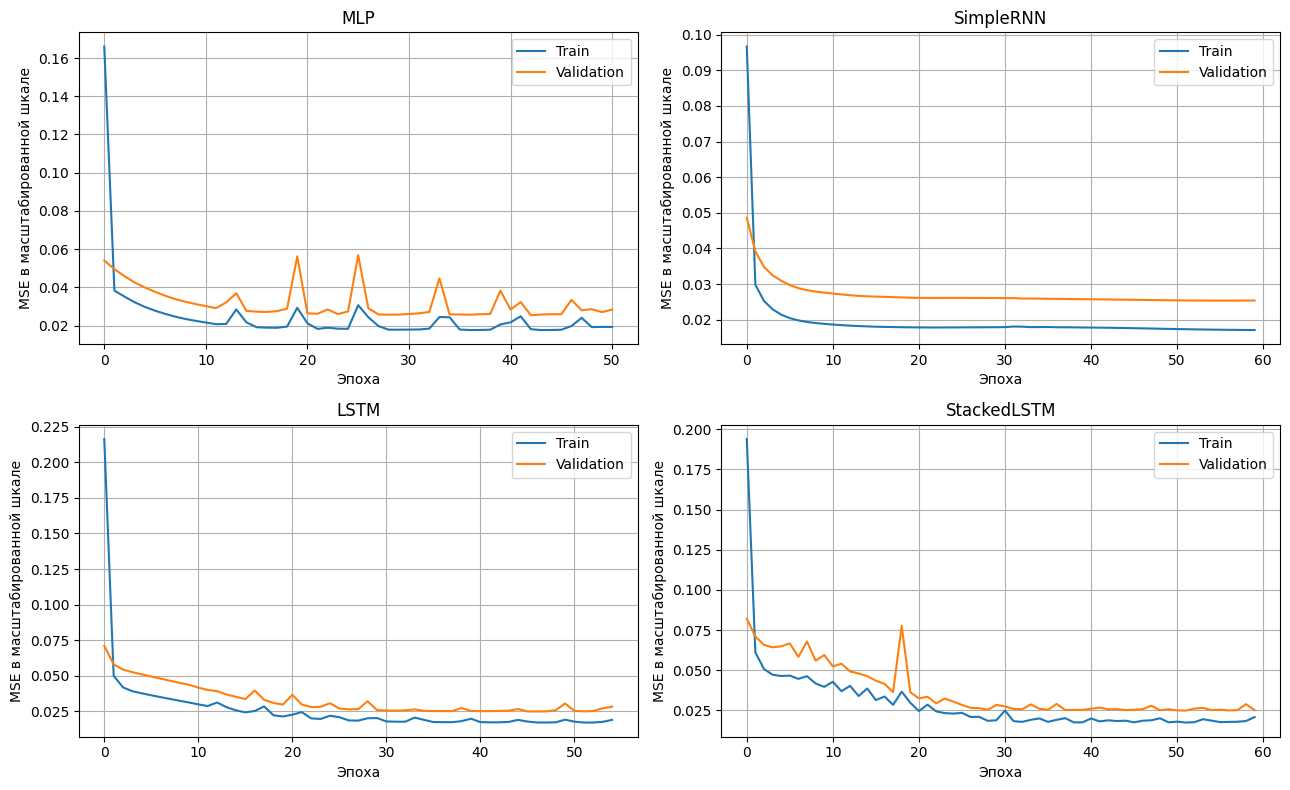

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, kind in zip(axes.ravel(), kinds):
    history = best_models[kind]["history"]

    ax.plot(history["loss"], label="Train")
    ax.plot(history["val_loss"], label="Validation")

    ax.set_title(kind)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("MSE в масштабированной шкале")
    ax.legend()

plt.tight_layout()
plt.show()

Графики выше - **кривые обучения (learning curves)** для каждой из четырёх нейросетевых архитектур на задаче прогноза на следующий день. Они показывают, как меняется ошибка модели в процессе обучения.

Линия Train (синяя) — ошибка на обучающей выборке (то, на чём модель учится).
Линия Validation (оранжевая) — ошибка на валидационной выборке (то, на чём модель НЕ учится, но проверяется).

По графикам видно, что:
1. **SimpleRNN** демонстрирует наиболее стабильное и эффективное обучение. Обе кривые (Train и Validation) быстро и плавно снижаются, сходясь к минимальным значениям (~0.018 и ~0.025 соответственно) уже к 10–15 эпохе. Минимальный разрыв между ними свидетельствует об отсутствии переобучения и отличной способности модели к обобщению.
2. **LSTM** показывает хорошее, но чуть менее стабильное обучение. Кривые снижаются плавно и монотонно, однако между Train и Validation сохраняется небольшой стабильный разрыв (~0.007), что указывает на лёгкое переобучение. Тем не менее Validation loss не растёт, а выходит на плато, что говорит о корректной работе EarlyStopping.
3. **StackedLSTM** обучается удовлетворительно, но с признаками нестабильности. Кривые в целом снижаются, однако на ~18-й эпохе наблюдается резкий выброс Validation loss (до ~0.078), после которого модель восстанавливается. Это указывает на чувствительность двухслойной архитектуры к «трудным» батчам и необходимость более тщательного подбора гиперпараметров.
4. **MLP** показывает наименее стабильное обучение среди всех моделей. Validation кривая имеет выраженные колебания с пиками до ~0.058 на протяжении всего обучения, а разрыв между Train и Validation остаётся заметным. Это типично для полносвязных сетей при работе с временными рядами: отсутствие рекуррентных связей затрудняет улавливание сезонных зависимостей, из-за чего процесс оптимизации становится неустойчивым. EarlyStopping сработал на ~50 эпохе, предотвратив дальнейшую деградацию.

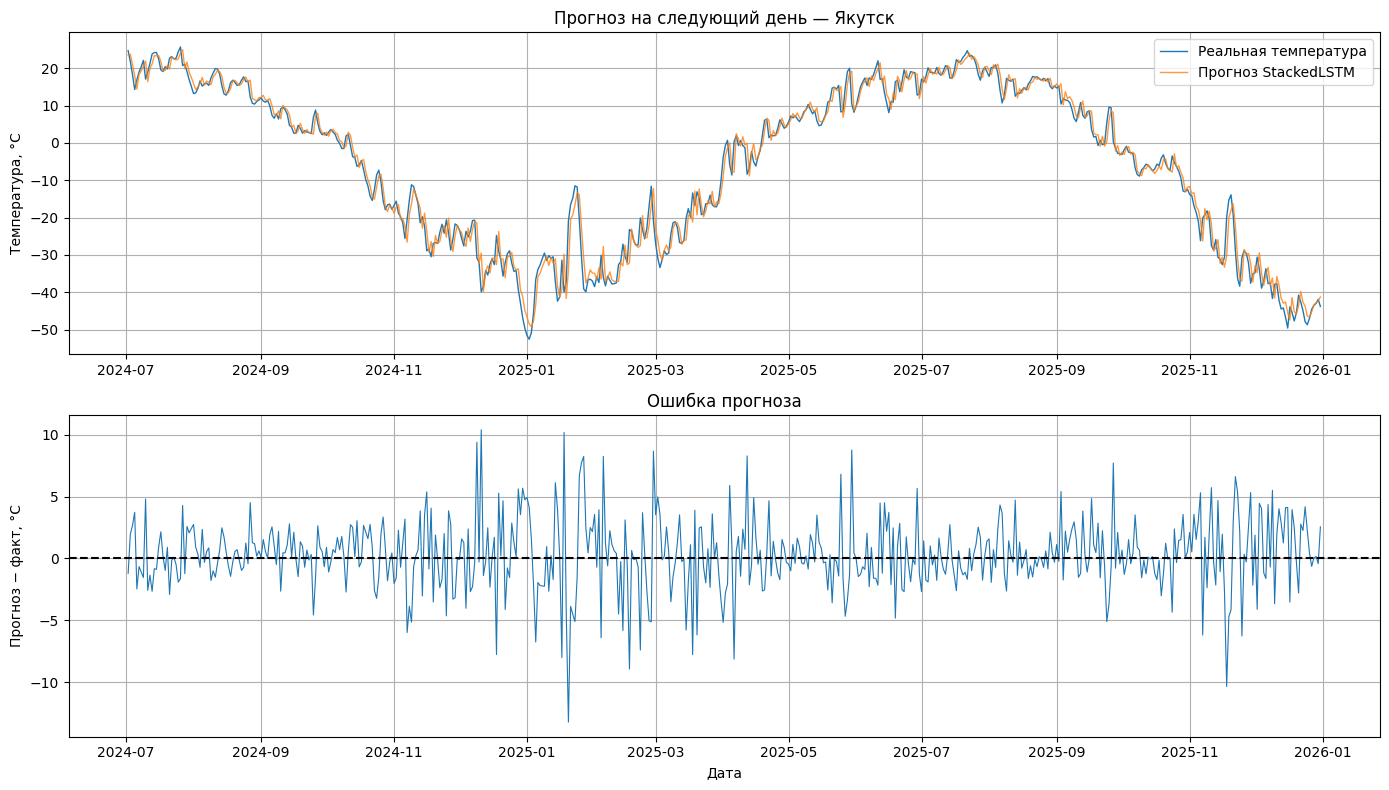

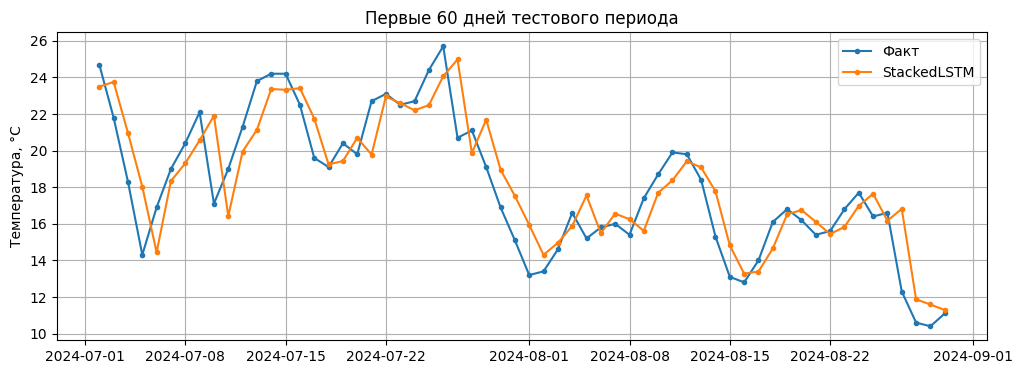

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(
    test_dates, actual,
    label="Реальная температура",
    linewidth=1,
)
axes[0].plot(
    test_dates, predictions[winner],
    label=f"Прогноз {winner}",
    linewidth=1,
    alpha=0.8,
)

axes[0].set_title(f"Прогноз на следующий день — {CITY}")
axes[0].set_ylabel("Температура, °C")
axes[0].legend()

errors = predictions[winner] - actual

axes[1].plot(test_dates, errors, linewidth=0.8)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Ошибка прогноза")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Прогноз − факт, °C")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(test_dates[:60], actual[:60], label="Факт", marker=".")
plt.plot(
    test_dates[:60],
    predictions[winner][:60],
    label=winner,
    marker=".",
)
plt.title("Первые 60 дней тестового периода")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

**Верхний график** показывает прогноз модели StackedLSTM на всём тестовом периоде (июль 2024 — январь 2026). Модель корректно воспроизводит ярко выраженный годовой сезонный цикл Якутска: летние максимумы около +20…+25°C и экстремальные зимние минимумы до −50°C. Прогноз практически сливается с фактической кривой, что свидетельствует о высоком качестве модели на горизонте одного дня.

**Нижний график** отображает ошибку прогноза (прогноз − факт). В подавляющем большинстве случаев ошибка лежит в диапазоне ±5°C, а систематического смещения не наблюдается — остатки колеблются около нулевой линии. Крупные выбросы (до ±10…13°C) приходятся на периоды резких температурных скачков, характерных для резко континентального климата Якутска (например, январь и ноябрь 2025 года). На детализированном графике первых 60 дней тестового периода видно, что модель точно следует за фактической динамикой, лишь незначительно запаздывая при очень резких перепадах температуры.

**Общий вывод:** StackedLSTM демонстрирует высокое качество прогноза температуры на следующий день (R² ≈ 0,981, MAE ≈ 2,1°C), успешно улавливая нелинейные сезонные зависимости и годовые циклы. Модель не имеет выраженного смещения, а крупные ошибки возникают преимущественно в моменты резких погодных изменений, что является естественным ограничением подхода на основе скользящего окна.

### 9.Сохранение результатов

``encoding="utf-8-sig"`` — для корректного открытия CSV в Excel с кириллицей.

Сохраняем: таблицу экспериментов, метрик и полные прогнозы. Это обеспечивает воспроизводимость.

In [12]:
experiment_table.to_csv(
    "experiments_next_day.csv",
    index=False,
    encoding="utf-8-sig",
)

result_table.to_csv(
    "metrics_next_day.csv",
    encoding="utf-8-sig",
)

forecast_table = pd.DataFrame({
    "Дата": test_dates,
    "Факт": actual,
    **predictions,
})

forecast_table.to_csv(
    "predictions_next_day.csv",
    index=False,
    encoding="utf-8-sig",
)


### 10. Ответы на контрольные вопросы

Ответы на вопросы 1 - 13 находятся в блокноте задачи А. Ответы на вопросы 14-25 в блокноте задачи B.

1. **Что такое временной ряд и какие компоненты сезонности и тренда могут присутствовать в метеорологических данных?**
Временной ряд — это последовательность наблюдений, упорядоченных по времени. В метеоданных выделяют:
* Тренд — долгосрочное изменение (например, потепление климата);
* Сезонность — регулярные колебания с периодом год (лето/зима), иногда суточные и недельные циклы;
* Циклическая компонента — колебания без фиксированного периода;
* Случайный шум — непредсказуемые отклонения.
2. **Чем прогнозирование временных рядов отличается от обычной регрессии на независимых наблюдениях?**
В регрессии наблюдения независимы и могут быть перемешаны. Во временных рядах наблюдения зависят от предыдущих (автокорреляция), поэтому:
* нельзя случайным образом делить выборку (иначе будет утечка из будущего);
* модель должна учитывать порядок и временную структуру;
* целевая переменная часто зависит от лагов самой себя.
3. **Что такое скользящее временное окно и как формируются входные последовательности?**
Скользящее окно длины L — это фрагмент ряда [T(t-L), ..., T(t-1)], который используется как вход для прогноза значения в момент t. Окно «скользит» по ряду с шагом 1, формируя много обучающих примеров. Для RNN вход имеет формат (batch, L, features), для MLP — (batch, L).
4. **Как длина входного окна влияет на качество прогноза?**
Короткое окно (L=7) — модель видит только локальный контекст, плохо улавливает сезонность.
Длинное окно (L=30–60) — модель захватывает месячный/сезонный паттерн, но требует больше данных и параметров.
Слишком длинное окно может привести к переобучению и шуму.
Оптимальная длина зависит от горизонта прогноза и периодичности ряда.
5. **Почему временной ряд нельзя случайным образом разделять на обучающую и тестовую выборки?**
Случайное перемешивание нарушает хронологию: в обучающую выборку могут попасть «будущие» наблюдения, а в тестовую — «прошлые». Модель получит информацию из будущего (утечка данных) и покажет нереалистично высокое качество на тесте, но будет бесполезна на реальных будущих данных.
6. **Что такое утечка данных в задаче прогнозирования временных рядов?**
Утечка данных — ситуация, когда модель при обучении получает информацию, которая в реальности была бы недоступна в момент прогноза. Примеры: использование будущих значений в признаках; масштабирование (StandardScaler) на всей выборке, включая test; интерполяция пропусков с привлечением будущих точек; случайное перемешивание при разбиении.
7. **Для чего масштабируют входные признаки и почему scaler обучают только на train?**
Масштабирование (StandardScaler, MinMaxScaler) нужно для:
* ускорения сходимости градиентного спуска;
* предотвращения доминирования признаков с большим диапазоном;
* стабильной работы функций активации.
Scaler обучают только на train, чтобы параметры масштабирования (mean, std) не содержали информации из validation/test — иначе возникнет утечка данных.
8. **Чем MLP отличается от SimpleRNN?**
MLP — полносвязная сеть прямого распространения. Вход — фиксированный вектор. Не учитывает порядок элементов, каждый вход обрабатывается независимо.
SimpleRNN — рекуррентная сеть. Вход — последовательность. Имеет скрытое состояние, которое передаётся от шага к шагу, что позволяет учитывать порядок и зависимости во времени.
9. **Как устроена рекуррентная связь в SimpleRNN?**
На каждом шаге t SimpleRNN вычисляет скрытое состояние: h(t) = activation(W·x(t) + U·h(t-1) + b), где x(t) — вход на шаге t, h(t-1) — скрытое состояние предыдущего шага, W, U, b — обучаемые параметры. Таким образом, информация «течёт» через время.
10. **Какие проблемы градиента затухающего и взрывающегося возникают при обучении RNN?**
При обратном распространении во времени (BPTT) градиент умножается на матрицу U много раз:
* Если собственные значения U < 1 → градиент затухает (vanishing gradient), модель не может обучиться долгосрочным зависимостям.
* Если собственные значения U > 1 → градиент взрывается (exploding gradient), веса нестабильны.
LSTM/GRU решают проблему затухания через механизмы gates.
11. **Какие элементы ячейки LSTM позволяют сохранять долгосрочную информацию?**
LSTM содержит три гейта и клеточное состояние C:
* Forget gate — решает, какую информацию из C забыть;
* Input gate — решает, какую новую информацию записать в C;
* Output gate — решает, какую часть C передать на выход;
* Cell state C — «магистраль», по которой информация течёт почти без изменений, что позволяет сохранять долгосрочные зависимости.
12. **Чем GRU отличается от LSTM?**
GRU — упрощённая версия LSTM:
* Два гейта вместо трёх: update gate (объединяет forget и input) и reset gate;
* Нет отдельного cell state — используется только скрытое состояние h;
* Меньше параметров → быстрее обучается, часто показывает сопоставимое качество.
13. **Для чего в первом слое stacked LSTM/GRU используют return_sequences=True?**
return_sequences=True заставляет слой возвращать последовательность скрытых состояний для каждого временного шага, а не только последнее. Это необходимо, чтобы следующий рекуррентный слой получил на вход полную последовательность, а не один вектор.